# Generative Adversarial Network (GAN) on MNIST
**Student Name:** Shaqeeq.S  
**Roll Number:** 24BAD109  

## Aim
To prepare the MNIST dataset, implement a Generator and Discriminator, train a GAN, and visualize/save synthetic handwritten digit images.

**Note:** Run the notebook from top to bottom. TensorFlow/Keras and Matplotlib are required. Training for 10 epochs is a practical demonstration; increase `EPOCHS` if more training time is available.

## Part A: Dataset Preparation and Image Preprocessing

In [1]:
# Student: Shaqeeq.S | Roll No: 24BAD109

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os
import random

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: 60000
Test images: 10000
Image dimensions: (28, 28)
Training labels shape: (60000,)


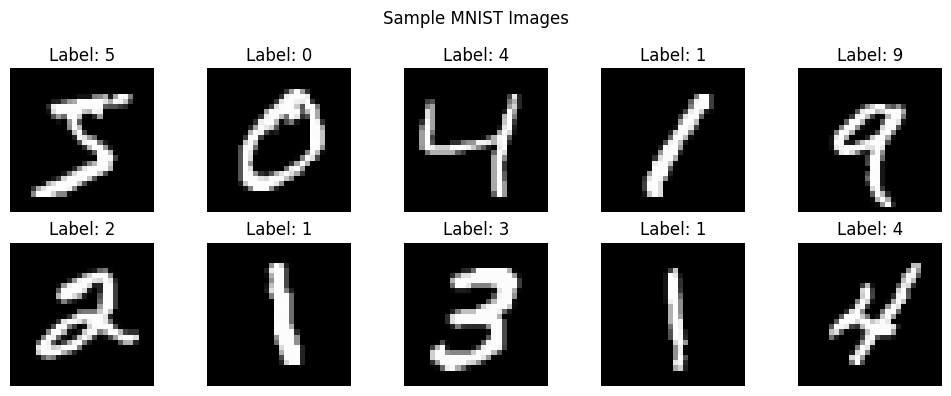

In [2]:
# Load the MNIST handwritten digit dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape[0])
print("Test images:", x_test.shape[0])
print("Image dimensions:", x_train.shape[1:])
print("Training labels shape:", y_train.shape)

# Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

In [3]:
# Normalize pixel values from [0, 255] to [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Reshape images to (28, 28, 1) for convolutional layers
x_train = np.expand_dims(x_train, axis=-1)

print("Preprocessed shape:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

# Prepare a batch-wise TensorFlow data pipeline
BATCH_SIZE = 128
BUFFER_SIZE = x_train.shape[0]

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Dataset pipeline created.")
print("Batch shape:", next(iter(train_dataset)).shape)

Preprocessed shape: (60000, 28, 28, 1)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Dataset pipeline created.
Batch shape: (128, 28, 28, 1)


## Part B: Implementing the Generator

In [4]:
# Student: Shaqeeq.S | Roll No: 24BAD109

NOISE_DIM = 100

def build_generator():
    model = keras.Sequential(name="Generator")
    model.add(layers.Input(shape=(NOISE_DIM,)))
    model.add(layers.Dense(7 * 7 * 128, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Reshape((7, 7, 128)))

    model.add(layers.Conv2DTranspose(
        64, kernel_size=4, strides=2, padding="same", use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Conv2DTranspose(
        1, kernel_size=4, strides=2, padding="same", activation="tanh"
    ))
    return model

generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

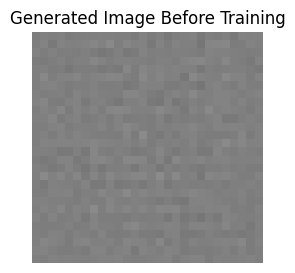

Generator output shape: (1, 28, 28, 1)


In [5]:
# Generate an image before GAN training
noise = tf.random.normal([1, NOISE_DIM])
generated_image = generator(noise, training=False)[0, :, :, 0].numpy()

plt.figure(figsize=(3, 3))
plt.imshow(generated_image, cmap="gray", vmin=-1, vmax=1)
plt.title("Generated Image Before Training")
plt.axis("off")
plt.show()

print("Generator output shape:", generator(noise).shape)

## Part C: Implementing the Discriminator and GAN Model

In [6]:
# Student: Shaqeeq.S | Roll No: 24BAD109

def build_discriminator():
    model = keras.Sequential(name="Discriminator")
    model.add(layers.Input(shape=(28, 28, 1)))
    model.add(layers.Conv2D(64, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1, activation="sigmoid"))
    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the Discriminator
discriminator_optimizer = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator.compile(
    optimizer=discriminator_optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Combine Generator and Discriminator to create the GAN.
# Freeze the Discriminator weights while training the combined GAN.
discriminator.trainable = False
gan_input = keras.Input(shape=(NOISE_DIM,), name="noise_input")
gan_output = discriminator(generator(gan_input))
gan = keras.Model(gan_input, gan_output, name="GAN")

gan.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5),
    loss="binary_crossentropy"
)

print("Generator summary:")
generator.summary()
print("Discriminator summary:")
discriminator.summary()
print("Combined GAN summary:")
gan.summary()

# Allow discriminator training separately in the training loop
discriminator.trainable = True

Generator summary:


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

...

Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noise_input (InputLayer)        │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       784,641 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 923,202 (3.52 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 151,233 (590.75 KB)

## Part D: GAN Training and Synthetic Image Generation

In [8]:
# Training settings
EPOCHS = 10
NUM_EXAMPLES = 25
OUTPUT_DIR = "gan_generated_images"
os.makedirs(OUTPUT_DIR, exist_ok=True)

fixed_noise = tf.random.normal([NUM_EXAMPLES, NOISE_DIM])
generator_losses = []
discriminator_losses = []

# Labels: real = 1, generated/fake = 0
real_labels = tf.ones((BATCH_SIZE, 1))
fake_labels = tf.zeros((BATCH_SIZE, 1))

print("Output folder:", OUTPUT_DIR)
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE)

Output folder: gan_generated_images
Epochs: 10 | Batch size: 128


Epoch 1/10 | D loss: 0.7380 | G loss: 0.3909


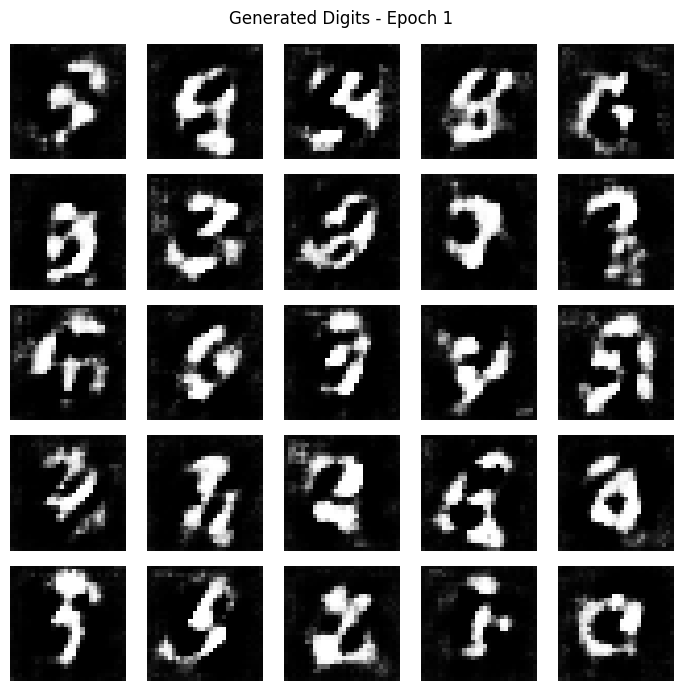

Saved: gan_generated_images/generated_epoch_001.png


In [ ]:
# Training loop: train Discriminator on real and fake images,
# then train Generator through the combined GAN.
for epoch in range(EPOCHS):
    d_epoch_losses = []
    g_epoch_losses = []

    for real_images in train_dataset:
        current_batch = tf.shape(real_images)[0]
        noise = tf.random.normal([current_batch, NOISE_DIM])
        fake_images = generator(noise, training=True)

        # Train Discriminator on real images
        real_y = tf.ones((current_batch, 1))
        fake_y = tf.zeros((current_batch, 1))

        d_loss_real = discriminator.train_on_batch(real_images, real_y)
        d_loss_fake = discriminator.train_on_batch(fake_images, fake_y)

        # Safely extract scalar loss values (avoiding len() on unsized 0-D arrays)
        if isinstance(d_loss_real, np.ndarray) and d_loss_real.ndim > 0:
            val_real = d_loss_real[0]
        elif isinstance(d_loss_real, (list, tuple)) and len(d_loss_real) > 0:
            val_real = d_loss_real[0]
        else:
            val_real = d_loss_real

        if isinstance(d_loss_fake, np.ndarray) and d_loss_fake.ndim > 0:
            val_fake = d_loss_fake[0]
        elif isinstance(d_loss_fake, (list, tuple)) and len(d_loss_fake) > 0:
            val_fake = d_loss_fake[0]
        else:
            val_fake = d_loss_fake

        # Average real/fake discriminator losses
        d_loss = (float(val_real) + float(val_fake)) / 2.0

        # Train Generator: it tries to make fake images classified as real
        misleading_labels = tf.ones((current_batch, 1))
        g_loss = gan.train_on_batch(noise, misleading_labels)

        # Safely extract generator loss (avoiding len() on unsized 0-D arrays)
        if isinstance(g_loss, np.ndarray) and g_loss.ndim > 0:
            val_g = g_loss[0]
        elif isinstance(g_loss, (list, tuple)) and len(g_loss) > 0:
            val_g = g_loss[0]
        else:
            val_g = g_loss

        d_epoch_losses.append(d_loss)
        g_epoch_losses.append(float(val_g))

    mean_d_loss = float(np.mean(d_epoch_losses))
    mean_g_loss = float(np.mean(g_epoch_losses))
    discriminator_losses.append(mean_d_loss)
    generator_losses.append(mean_g_loss)

    print(f"Epoch {epoch + 1}/{EPOCHS} | D loss: {mean_d_loss:.4f} | G loss: {mean_g_loss:.4f}")

    # Save and display generated images at regular intervals
    if (epoch + 1) % 2 == 0 or epoch == 0 or epoch == EPOCHS - 1:
        predictions = generator(fixed_noise, training=False).numpy()
        grid = (predictions + 1.0) / 2.0

        fig, axes = plt.subplots(5, 5, figsize=(7, 7))
        for i, ax in enumerate(axes.flat):
            ax.imshow(grid[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
            ax.axis("off")
        fig.suptitle(f"Generated Digits - Epoch {epoch + 1}")
        plt.tight_layout()
        image_path = os.path.join(OUTPUT_DIR, f"generated_epoch_{epoch + 1:03d}.png")
        plt.savefig(image_path, dpi=150, bbox_inches="tight")
        plt.show()
        print("Saved:", image_path)

In [ ]:
# Plot Generator and Discriminator losses
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), generator_losses, marker="o", label="Generator Loss")
plt.plot(range(1, EPOCHS + 1), discriminator_losses, marker="o", label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Generate final synthetic images and save them
final_images = generator(tf.random.normal([25, NOISE_DIM]), training=False).numpy()
final_images_display = (final_images + 1.0) / 2.0

fig, axes = plt.subplots(5, 5, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(final_images_display[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
fig.suptitle("Final Synthetic MNIST Images")
plt.tight_layout()
final_grid_path = os.path.join(OUTPUT_DIR, "final_generated_images.png")
plt.savefig(final_grid_path, dpi=150, bbox_inches="tight")
plt.show()

# Save individual generated images as NumPy data and the trained Generator
np.save(os.path.join(OUTPUT_DIR, "final_generated_images.npy"), final_images)
generator.save(os.path.join(OUTPUT_DIR, "trained_generator.keras"))

print("Saved final image grid:", final_grid_path)
print("Saved individual images array: final_generated_images.npy")
print("Saved trained Generator: trained_generator.keras")

In [ ]:
# Compare real images with final generated images
real_images_batch = next(iter(train_dataset)).numpy()
real_display = (real_images_batch[:10] + 1.0) / 2.0
fake_display = final_images_display[:10]

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(real_display[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title("Real")
    axes[0, i].axis("off")

    axes[1, i].imshow(fake_display[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("Generated")
    axes[1, i].axis("off")

plt.suptitle("Real MNIST Images vs Generated Images")
plt.tight_layout()
plt.show()

## Results and Conclusion

- MNIST images were loaded, explored, normalized to `[-1, 1]`, reshaped to `(28, 28, 1)`, and prepared in batches.
- A Generator was implemented to transform random noise vectors into 28 × 28 grayscale images.
- A Discriminator was implemented to classify images as real or generated.
- The GAN was trained using adversarial learning, and both losses were recorded.
- Synthetic image grids were displayed at training intervals and saved in the `gan_generated_images` folder.
- Compare the real and generated samples to discuss image quality and diversity. With only 10 epochs, some generated images may be unclear; longer training can improve results.

**Submission evidence:** Run each section and take screenshots of the code and corresponding outputs. The notebook includes the student name and roll number in the heading and code sections.